# Confronto OREX vs NEOREX-S vs NEOREX-R (T8 L8 r8, nsteps=6)

- `OREX` e `NEOREX-S` sono letti da `orex_vs_neorex_pretrained_metrics.csv`.
- `NEOREX-R` usa i valori finali del run residuale condiviso (`final_swap_acceptance_mean`, `final_work_mean`).


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.dpi"] = 120


In [2]:
base_dir = Path(".")
if not (base_dir / "orex_vs_neorex_pretrained_metrics.csv").exists():
    base_dir = Path("plot/orex_recovered_from_txt")

csv_path = base_dir / "orex_vs_neorex_pretrained_metrics.csv"
df = pd.read_csv(csv_path)

mask = (df["nreplicas"] == 8) & (df["nsteps"] == 6)
orex_row = df[mask & (df["algorithm"] == "orex")].iloc[0]
neorex_s_row = df[mask & (df["algorithm"] == "neorex")].iloc[0]

summary = pd.DataFrame(
    [
        {
            "model": "OREX",
            "swap_acceptance": float(orex_row["swap_acceptance"]),
            "work_mean": float(orex_row["work_mean"]),
            "source": "orex_vs_neorex_pretrained_metrics.csv",
        },
        {
            "model": "NEOREX-S",
            "swap_acceptance": float(neorex_s_row["swap_acceptance"]),
            "work_mean": float(neorex_s_row["work_mean"]),
            "source": "orex_vs_neorex_pretrained_metrics.csv",
        },
        {
            "model": "NEOREX-R",
            "swap_acceptance": 0.655960,
            "work_mean": 0.4137022,
            "source": "production_neorex_residual_obc_T8_L8_r8... (log utente)",
        },
    ]
)

summary = summary.set_index("model").loc[["OREX", "NEOREX-S", "NEOREX-R"]].reset_index()
summary


,model,swap_acceptance,work_mean,source
0,OREX,0.625156,0.492444,orex_vs_neorex_pretrained_metrics.csv
1,NEOREX-S,0.648393,0.428084,orex_vs_neorex_pretrained_metrics.csv
2,NEOREX-R,0.655960,0.413702,production_neorex_residual_obc_T8_L8_r8... (lo...


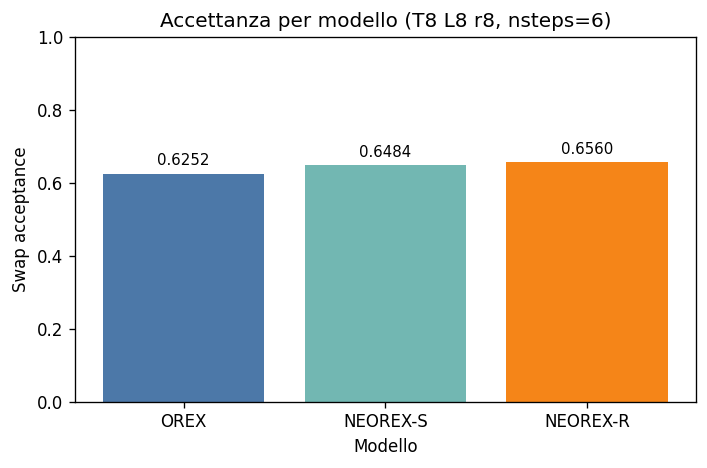

In [3]:
colors = ["#4C78A8", "#72B7B2", "#F58518"]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(summary["model"], summary["swap_acceptance"], color=colors)
ax.set_xlabel("Modello")
ax.set_ylabel("Swap acceptance")
ax.set_title("Accettanza per modello (T8 L8 r8, nsteps=6)")
ax.set_ylim(0.0, 1.0)

for i, value in enumerate(summary["swap_acceptance"]):
    ax.text(i, value + 0.015, f"{value:.4f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()


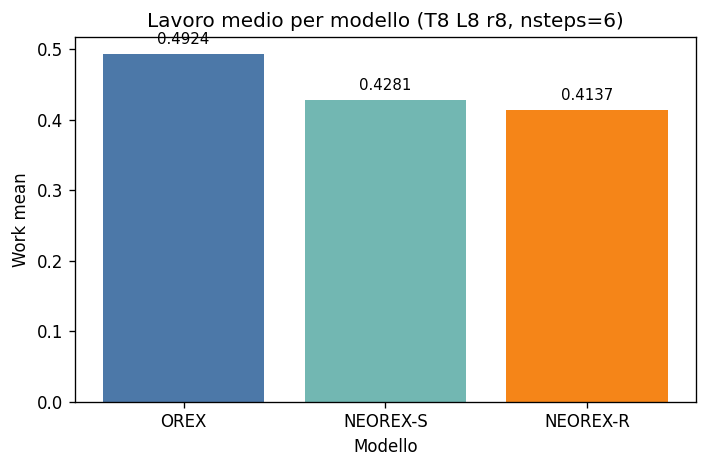

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(summary["model"], summary["work_mean"], color=colors)
ax.set_xlabel("Modello")
ax.set_ylabel("Work mean")
ax.set_title("Lavoro medio per modello (T8 L8 r8, nsteps=6)")

for i, value in enumerate(summary["work_mean"]):
    ax.text(i, value + 0.01, f"{value:.4f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()
